# Science case: TDAMM follow-up (transient classification)

Time-domain and multi-messenger (TDAMM) follow-up with a spectrograph is about
**classification** and **follow-up**: we will focus on the former in this notebook.
Classification typically uses a low-SNR spectrum, rebinned to R ~ 100-300, that can distinguish a SN Ia from a
SN II or a TDE from an AGN flare. The relevant question for LFAST
is: *what is the faint limit to classify a transient in a given exposure?* All times below are
on-target integration; slew, acquisition and other response-time overheads are not modelled.

**Assumptions used in this notebook**:

* Classification needs SNR ~ 5 per **rebinned** element at R_bin = 300 across 450-650 nm, the
  regime low-resolution classifiers are designed for (SEDM: Blagorodnova et al. 2018; 4MOST/TiDES:
  Swann et al. 2019). Co-adding $k = R/R_{bin}$ adjacent resels of equal SNR raises the SNR by
  $\sqrt{k}$ in this noise model (every variance term scales with the number of pixels).
* 60 minutes is taken as the practical upper limit on the time spent on one classification spectrum.
* Instrument mode: one Bench setting, the R ~ 1800 preset (`bench_r1800`, 412-686 nm), with
  classification over 450-650 nm. This is only one of the Bench's grating and order settings
  (https://www.wiyn.org/Instruments/wiynbench.html); others cover redder or wider ranges at different
  resolution and ship as `bench_*` presets (`list_instruments()`). Several statements below about the 450-650 nm window are properties of this mode,
  and exploring other modes is left as an exercise (see the end of the notebook).
* Transient SEDs (blackbodies): a hot 25,000 K source (young SN II / TDE), a 10,000 K source
  (SN Ia near peak, where $B-V \approx 0$; Phillips et al. 1999) and a red 3500 K source (kilonova at ~3 d, luminous red
  nova). Their magnitudes are **R** (Cousins, Vega; within ~0.1-0.2 mag of SDSS r for these colours),
  so the SED colour matters in the 450-650 nm window.
* GRB afterglow: a power law $F_\nu \propto \nu^{-0.7}$ (mean optical slope 0.66; Kann et al. 2010), fading as $t^{-\alpha}$ with $\alpha \approx 1$.
  Afterglow magnitudes are **AB**, as is usual in the GRB literature. For afterglows the metric is a
  redshift, not a classification (see that section).
* Kilonova: AT2017gfo-like, r = 17.3 at 0.5 d at 40 Mpc, fading 0.95 mag per day in r over the
  first 5 days (Drout et al. 2017, Table S2), cooling from ~10,000 K at 0.5 d to ~5000 K at
  1.5 d and approaching ~2500 K after ~5 d (Drout et al. 2017; Shappee et al. 2017). We only use the
  first 5 days, where this description holds.
* The sky background assumption is grey time (moon up); dark-time depths are ~0.3-0.5 mag deeper at the
  faint end (see the sensitivity-map notebook). Grey time is a fair average for target-of-opportunity
  follow-up, where the moon phase cannot be chosen.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lfast_etc import LFASTETC, Source, Telescope, Instrument, Sky, list_instruments
from lfast_etc.plotting import plot_snr_map, plot_limiting_magnitude, plot_vs_n_telescopes, equivalent_diameter_axis
try:
    plt.style.use('gks')      # the author's matplotlib style; skipped if you do not have it
except OSError:
    pass

In [2]:
# ---- knobs ----
N_TEL = 20
WINDOW = (450, 650)          # nm, classification window
R_BIN = 300                  # rebinned resolution for classification
SNR_CLASS = 5                # SNR per R_BIN element needed to classify
EXP_MAX = 3600               # s, practical upper limit for one classification spectrum
BAND = "R"                   # magnitudes in Cousins R (~ SDSS r)

bench = LFASTETC("bench_r1800", n_telescopes=N_TEL, wavelength_min_nm=WINDOW[0], wavelength_max_nm=WINDOW[1])
k = bench.instrument.resolving_power / R_BIN   # resels per rebinned element
snr_resel_needed = SNR_CLASS / np.sqrt(k)      # SNR per native resel that gives SNR_CLASS at R_BIN
print(f"{k:.1f} resels per R={R_BIN} bin -> need SNR {snr_resel_needed:.2f} per resel")

seds = {"hot 25,000 K": Source.blackbody(25000, 0, BAND),
        "SN Ia 10,000 K": Source.blackbody(10000, 0, BAND),
        "red 3500 K": Source.blackbody(3500, 0, BAND),
        "afterglow (AB)": Source.powerlaw(-0.7, 0, BAND, system="AB")}

6.0 resels per R=300 bin -> need SNR 2.04 per resel


## Exposure time to classify versus magnitude

The curves give the integration time needed to reach the classification SNR for each SED. The
reference magnitudes are the Argus Array detection depths (g, 5 sigma, dark time; science
requirements from the Argus specifications, argus.unc.edu/specifications; Law et al. 2022), since
Argus is (one of) the discovery engine(s) LFAST would follow up:

* **g = 20.0**, the single-epoch (1-minute) depth;
* **g = 21.5**, the 15-minute co-add depth.

These are detection limits, not classification limits, and they are in g (AB) while the curves are in
R (Vega). For SN-like colours near peak $g \approx r$, and R (Vega) is ~0.2 mag brighter than r (AB);
both offsets are ignored here.

SN Ia: at Argus 1 min depth (20.0): 6.7 min;  at Argus 15 min depth (21.5): 59.7 min


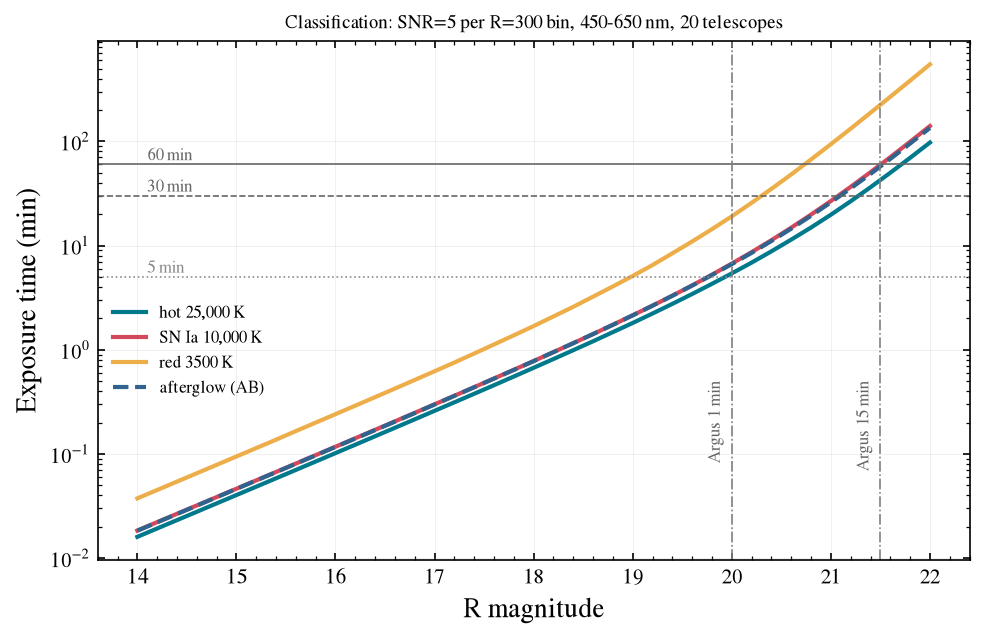

In [3]:
mags = np.linspace(14, 22, 41)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for label, src in seds.items():
    t = bench.exptime_vs_mag(src, mags, snr=snr_resel_needed, wavelength=WINDOW)
    ax.plot(mags, t/60, label=label, ls='--' if 'afterglow' in label else '-')
ax.set_yscale('log'); ax.set_xlabel(f"{BAND} magnitude"); ax.set_ylabel("Exposure time (min)")
for tmin, ls, c in ((60, '-', '0.4'), (30, '--', '0.4'), (5, ':', '0.55')):
    ax.axhline(tmin, color=c, ls=ls, lw=0.8); ax.text(14.1, tmin*1.1, f"{tmin} min", fontsize=8, color=c)
ARGUS = {"Argus 1 min": 20.0, "Argus 15 min": 21.5}   # g, 5 sigma, dark time (science requirements)
for txt, mag in ARGUS.items():
    ax.axvline(mag, color='0.5', ls='-.', lw=0.8); ax.text(mag-0.08, 0.5, txt, fontsize=8, color='0.4', rotation=90, ha='right', va='top')
ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(0.0, 0.52))
ax.set_title(f"Classification: SNR={SNR_CLASS} per R={R_BIN} bin, {WINDOW[0]}-{WINDOW[1]} nm, {N_TEL} telescopes", fontsize=9)

t_ref = bench.exptime_vs_mag(seds["SN Ia 10,000 K"], list(ARGUS.values()), snr=snr_resel_needed, wavelength=WINDOW)
print("SN Ia: " + ";  ".join(f"at {txt} depth ({mag}): {t/60:.1f} min" for (txt, mag), t in zip(ARGUS.items(), t_ref)))

With 20 telescopes a SN Ia-like SED at the Argus 1 minute depth needs about 7 minutes, and one at the
15-minute co-add depth needs about an hour, right at the classification budget. The nominal array
could therefore classify what Argus finds in single epochs and the bright end of its 15-minute co-adds.
Because transient counts rise towards fainter magnitudes, a large share of the Argus detections
will sit close to these limits.

## Classification depth versus exposure time

The table gives the faintest R magnitude that can be classified in 5, 15, 30 and 60 minutes (i.e. assuming SNR=5).

In [4]:
exps = (300, 900, 1800, 3600)
depth = pd.DataFrame({label: [bench.limiting_magnitude(src, t, snr_resel_needed, wavelength=WINDOW) for t in exps]
                      for label, src in seds.items()},
                     index=pd.Index([t // 60 for t in exps], name="exposure (min)"))
depth.round(1)

,"hot 25,000 K","SN Ia 10,000 K",red 3500 K,afterglow (AB)
exposure (min),,,,
5,19.9,19.8,19.0,19.8
15,20.8,20.6,19.8,20.6
30,21.3,21.1,20.3,21.1
60,21.7,21.5,20.7,21.5


Note:
* **Exposure time.** Doubling the exposure from 30 to 60 min gains only ~0.4 mag. That is the
  background-limited scaling ($\Delta m = 1.25\log_{10} 2 \approx 0.38$): at these magnitudes the sky
  and detector noise dominate, so SNR grows as $\sqrt{t}$ rather than as $t$. The step from 5 to
  15 min is somewhat steeper because read noise still matters in the shortest exposures. Going
  beyond 60 min buys little: the next half-magnitude would cost another ~1.5 h.

## How many days after merger can we still classify kilonovae?

Assumptions (AT2017gfo-like, at 40 Mpc):
* r = 17.3 at 0.5 d,
* fading 0.95 mag/day in r,
* cooling 10,000 K -> 5000 K -> 2500 K at 0.5, 1.5 and 5.5 d (linear ramps);

We stop at 5 d, the end of the range this light curve describes. 
We scale to other distances with the distance modulus and ask for a classification
spectrum (SNR=5 at R=300). 

40 Mpc is GW170817 itself; for reference the LIGO binary-neutron-star
range is 150-170 Mpc in O4 and 225-295 Mpc planned for O5 (the classification horizon versus
array size is in the LSST-era time-domain notebook). The blackbody is normalised in R.

 40 Mpc: classifiable until 3.7 d (30 min) / 4.1 d (60 min)
100 Mpc: classifiable until 1.9 d (30 min) / 2.3 d (60 min)
200 Mpc: classifiable until 0.7 d (30 min) / 1.1 d (60 min)


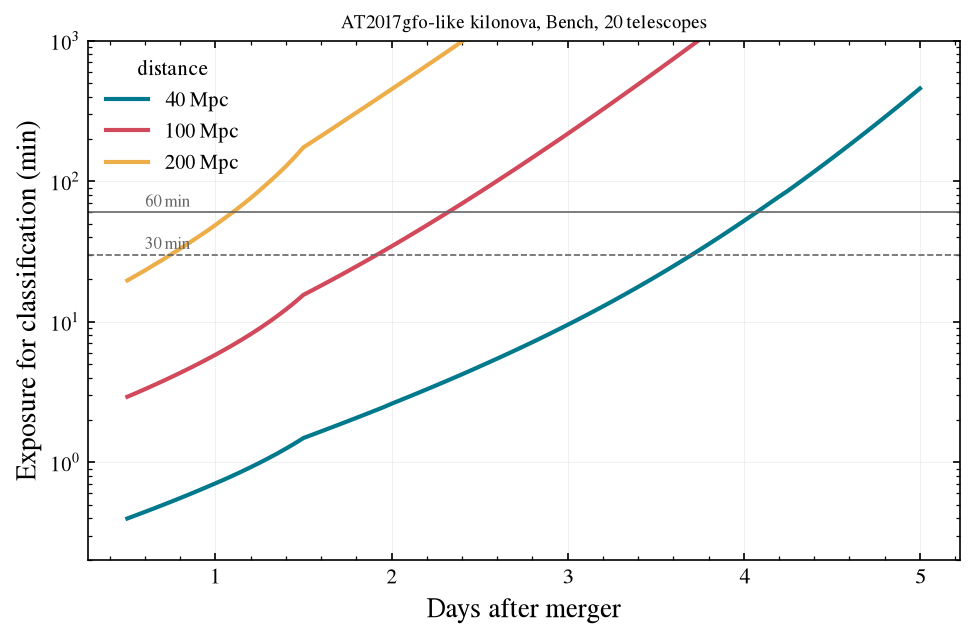

In [5]:
days = np.linspace(0.5, 5, 91)
def kn_mag(d, D_Mpc):
    return 17.3 + 0.95*(d-0.5) + 5*np.log10(D_Mpc/40)
def kn_teff(d):
    return np.interp(d, [0.5, 1.5, 5.5], [10000, 5000, 2500])

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for D in (40, 100, 200):
    t_needed = np.array([bench.exptime_vs_mag(Source.blackbody(kn_teff(d), 0, BAND), [kn_mag(d, D)],
                                              snr=snr_resel_needed, wavelength=WINDOW)[0] for d in days]) / 60
    ax.plot(days, t_needed, label=f"{D} Mpc")
    last = {tmin: days[t_needed <= tmin].max() if (t_needed <= tmin).any() else np.nan for tmin in (30, 60)}
    print(f"{D:3d} Mpc: classifiable until {last[30]:.1f} d (30 min) / {last[60]:.1f} d (60 min)")
ax.axhline(60, color='0.4', lw=0.8); ax.text(0.6, 66, "60 min", fontsize=8, color='0.4')
ax.axhline(30, color='0.4', ls='--', lw=0.8); ax.text(0.6, 33, "30 min", fontsize=8, color='0.4')
ax.set_yscale('log'); ax.set_ylim(0.2, 1e3); ax.set_xlabel("Days after merger"); ax.set_ylabel("Exposure for classification (min)")
ax.legend(title="distance"); ax.set_title(f"AT2017gfo-like kilonova, Bench, {N_TEL} telescopes", fontsize=9);

A GW170817-like event at 40 Mpc stays classifiable for almost four days; at 100 Mpc the
window is about two nights, and at 200 Mpc (O5-like distances) only the first night, in this mode.
The kilonova fades by ~1 mag/day and also cools, moving its flux redward of the 450-650 nm window.
A redder Bench setting would follow it further; how much longer that keeps a kilonova classifiable
is left as an exercise (see the end of the notebook).

## GRB afterglows: time to a redshift

For an afterglow the gamma-ray or X-ray trigger typically already broadly indicates what the transient is; what the
spectrum adds is the **redshift**. It comes from absorption lines that the host-galaxy gas and any
intervening absorbers imprint on the afterglow continuum: Mg II 2796/2803 and Fe II at z <~ 2 and,
at higher redshift, the C IV and Si II lines, Ly-alpha / damped Ly-alpha absorption and the Ly-alpha
forest (Fynbo et al. 2009). Between them these put strong lines in the 450-650 nm window for
z ~ 0.6-4; other Bench settings shift or widen that redshift range. The strong lines have rest-frame equivalent widths of ~1-4 A (Mg II doublet ~3.8 A, C IV ~2.4 A, Fe II 2600 ~1.8 A, Si II 1527 ~1.0 A; de Ugarte Postigo et al. 2012), and the observed
equivalent width is larger by (1+z). At R = 1800 a resel is ~3 A at 550 nm, so a continuum SNR of
~10 per **native** resel (no rebinning) measures an equivalent width to ~0.3 A and detects Fe II 2600
at z = 1 (3.6 A observed) at ~10 sigma. That is the metric used here.

Afterglows fade as $F \propto t^{-\alpha}$ with $\alpha \approx 1$. The curves are for afterglows at
R = 17, 19 and 21 (AB) one hour after the burst. For afterglows detected within the first hour the
R magnitude at 1 h is distributed around R ~ 18.4 with a width of ~1.6 mag (Wang et al. 2013, Vega;
AB is ~0.2 mag fainter), so these curves span roughly +-1.5 sigma of that population. Optically dark
bursts are fainter still and are not reachable. The source is held at its
brightness at the start of the exposure, which is optimistic once the exposure becomes comparable
to the delay.

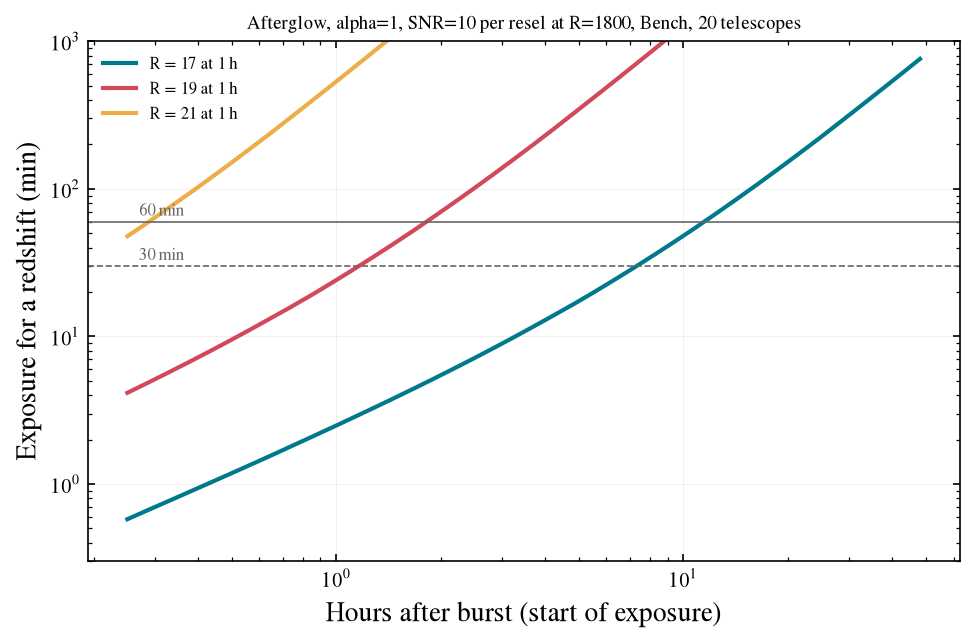

In [6]:
SNR_Z = 10                    # SNR per native resel for an absorption-line redshift
delay_h = np.logspace(np.log10(0.25), np.log10(48), 40)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for m1h in (17, 19, 21):
    mag_t = m1h + 2.5*1.0*np.log10(delay_h/1.0)
    t_z = bench.exptime_vs_mag(seds["afterglow (AB)"], mag_t, snr=SNR_Z, wavelength=WINDOW)
    ax.plot(delay_h, t_z/60, label=f"R = {m1h} at 1 h")
ax.axhline(60, color='0.4', lw=0.8); ax.text(0.27, 66, "60 min", fontsize=8, color='0.4')
ax.axhline(30, color='0.4', ls='--', lw=0.8); ax.text(0.27, 33, "30 min", fontsize=8, color='0.4')
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_ylim(0.3, 1e3)
ax.set_xlabel("Hours after burst (start of exposure)"); ax.set_ylabel("Exposure for a redshift (min)")
ax.legend(fontsize=8)
ax.set_title(f"Afterglow, alpha=1, SNR={SNR_Z} per resel at R=1800, Bench, {N_TEL} telescopes", fontsize=9);

A bright afterglow (R = 17 at 1 h) gives a redshift in a couple of minutes at one hour and is
still within an hour's integration up to ~11 h after the burst. An R = 19 afterglow needs to be
observed within ~2 h of the burst, and an R = 21 afterglow is out of reach of the nominal array except in
the first ~20 minutes.

## Array size trade for TDAMM depth (60 min, classification SNR)

The 20-telescope prototype is the nominal array; 100 and 200 telescopes are two possible upgrades.
In this model the telescopes are fiber-combined in groups of 20 (one combiner per array, as in
`Telescope(telescopes_per_input=20)`); each combiner output is a separate spectrograph input,
read out separately and co-added. Source and sky photons therefore grow with N, and so do dark
current and read noise (with the number of inputs, N/20). At the faint end every noise term grows in
proportion to the signal, so SNR $\propto \sqrt{N}$ and the depth improves by
$\Delta m = 1.25\log_{10}(N/20)$: about 0.9 mag for 100 telescopes and 1.25 mag for 200. That is half
the $2.5\log_{10}(N/20)$ that the collecting area alone would suggest. A single combiner feeding all
N telescopes into one input would do better (see the array-scaling notebook). The table gives the
60-minute classification depth for each SED.

In [7]:
rows = {}
for n in (20, 100, 200):
    e = LFASTETC("bench_r1800", n_telescopes=n, wavelength_min_nm=WINDOW[0], wavelength_max_nm=WINDOW[1])
    rows[n] = {"D_eq (m)": e.telescope.equivalent_diameter_m, "inputs": e.telescope.n_inputs,
               **{label: e.limiting_magnitude(src, EXP_MAX, snr_resel_needed, wavelength=WINDOW) for label, src in seds.items()}}
trade = pd.DataFrame(rows).T.rename_axis("N telescopes")
trade["inputs"] = trade["inputs"].astype(int)
trade["gain vs N=20 (mag)"] = trade["SN Ia 10,000 K"] - trade.loc[20, "SN Ia 10,000 K"]
trade.round(2)

,D_eq (m),inputs,"hot 25,000 K","SN Ia 10,000 K",red 3500 K,afterglow (AB),gain vs N=20 (mag)
N telescopes,,,,,,,
20,3.25,1,21.71,21.50,20.73,21.53,0.00
100,7.26,5,22.61,22.40,21.63,22.42,0.89
200,10.27,10,22.99,22.78,22.01,22.80,1.28


Going from 20 to 200 telescopes pushes the 60-minute SN Ia classification depth from
R ~ 21.5, at the Argus 15-minute co-add depth, to R ~ 22.8, about a magnitude beyond it **assuming the Bench spectrograph**. For the kilonova, 1.25 mag is a factor ~1.8 in distance, so the
200-telescope array reaches at 200 Mpc roughly what the nominal array reaches at ~110 Mpc.

## Things to try

**Other Bench modes.** Everything above uses one Bench setting. The Bench offers many grating and
order combinations (https://www.wiyn.org/Instruments/wiynbench.html), from coarse gratings covering
~500 nm in one setting to high-resolution orders covering ~25 nm, and they ship as `bench_*` presets
(`list_instruments()`). Redder settings suit cool sources (later phases in kilonovae, red transients)
and higher-redshift afterglow lines; bluer ones suit hot, young transients. Suggestions:

* how many more days a kilonova stays classifiable in a redder mode;
* how the colour ordering of the SEDs changes;
* which afterglow redshifts each setting covers.

The `bench_*` presets scale the spectrograph efficiency from the WIYN table, but the detector QE is
a flat 0.75 placeholder, so results at the red end are indicative.

**Other knobs.**

* Raise `SNR_CLASS` to 10, the level at which a SN Ia subtype can be told apart. How much depth
  does that cost?
* Use `Sky(scale=0.4)` for dark time and redo the kilonova plot. Does the 200 Mpc curve cross the
  30 minute line?